In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\DELL\Desktop\Programming\Data analytics\work\E-commerce sales analytics\customer_master.csv")

In [9]:
df.head()

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


In [62]:
row, column = df.shape
print(f"The table has {column} columns and {row} rows ")
print("-----------Description---------------")
df.describe()

The table has 11 columns and 25000 rows 
-----------Description---------------


,customer_age,customer_postal_code,customer_acquisition_cost
count,25000.000000,25000.000000,25000.000000
mean,45.907840,50183.066400,42.159750
std,16.454286,28596.584321,21.692648
min,18.000000,516.000000,5.010000
25%,32.000000,25374.500000,23.297500
50%,46.000000,50303.000000,41.980000
75%,60.000000,74845.500000,61.130000
max,74.000000,99950.000000,79.990000


In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  object 
 1   customer_name              25000 non-null  object 
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  object 
 4   customer_segment           25000 non-null  object 
 5   customer_city              25000 non-null  object 
 6   customer_state             25000 non-null  object 
 7   customer_country           25000 non-null  object 
 8   region                     25000 non-null  object 
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), object(8)
memory usage: 2.1+ MB


In [76]:
print("-----------Nulls---------------")
print(df.isnull().sum())
print("-----------NA---------------")

print(df.isna().sum())
print("------------Duplicates----------------")

df.duplicated().sum()
print(f"Duplicate customer_id: {df['customer_id'].duplicated().sum()}")

-----------Nulls---------------
customer_id                  0
customer_name                0
customer_age                 0
gender                       0
customer_segment             0
customer_city                0
customer_state               0
customer_country             0
region                       0
customer_postal_code         0
customer_acquisition_cost    0
dtype: int64
-----------NA---------------
customer_id                  0
customer_name                0
customer_age                 0
gender                       0
customer_segment             0
customer_city                0
customer_state               0
customer_country             0
region                       0
customer_postal_code         0
customer_acquisition_cost    0
dtype: int64
------------Duplicates----------------
Duplicate customer_id: 0


In [91]:
df['customer_country'].unique()

array(['UAE', 'Germany', 'USA', 'UK', 'India', 'Canada', 'Australia'],
      dtype=object)

### Segment Distribution
#### How the customer base splits across the four named segments.

In [97]:
df['customer_segment'].unique()

array(['Consumer', 'VIP', 'Premium', 'Business'], dtype=object)

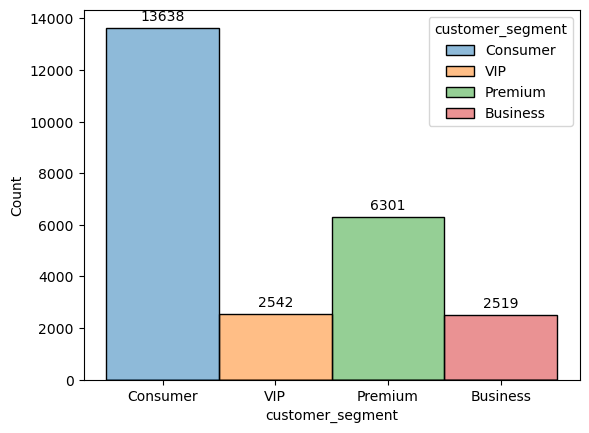

In [112]:
ax = sns.histplot(data=df, x='customer_segment', kde=True, hue='customer_segment')

# 2. Iterate through the containers to add the labels
for container in ax.containers:
    # 3. Create a custom label list that replaces '0' with an empty string
    labels = [f'{int(v.get_height())}' if v.get_height() > 0 else '' for v in container]
    
    # 4. Apply the labels to the chart
    ax.bar_label(container, labels=labels, padding=3)

plt.show()

In [125]:
segment_counts = df.groupby('customer_segment', as_index=False).agg({"customer_id": "count"})

In [127]:
segment_counts

,customer_segment,customer_id
0,Business,2519
1,Consumer,13638
2,Premium,6301
3,VIP,2542


In [133]:
segment_counts['percentage'] = np.round((segment_counts['customer_id'] / segment_counts['customer_id'].sum()) * 100,2)

In [135]:
segment_counts

,customer_segment,customer_id,percentage
0,Business,2519,10.08
1,Consumer,13638,54.55
2,Premium,6301,25.20
3,VIP,2542,10.17


In [152]:
# Calculate percentages automatically
percentages = df['customer_segment'].value_counts(normalize=True).reset_index()

# Rename columns and format as a standard percentage
percentages.columns = ['customer_segment', 'percentage']
percentages['percentage'] = np.round(percentages['percentage'] * 100,2)

In [154]:
percentages

,customer_segment,percentage
0,Consumer,54.55
1,Premium,25.20
2,VIP,10.17
3,Business,10.08


## Country and Region Structure
### Seven countries are represented, at very different scales.

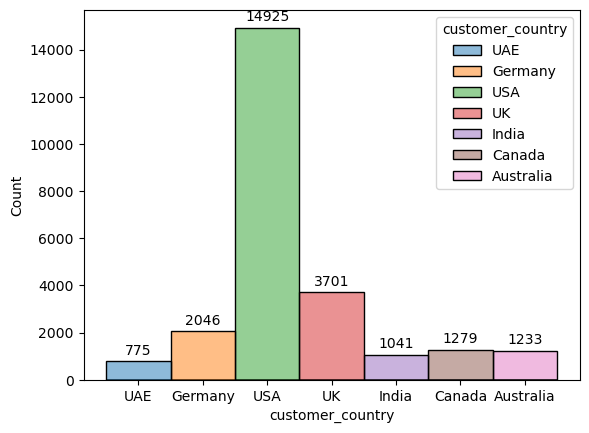

In [172]:
country_counts = df['customer_country'].value_counts().index

ax = sns.histplot(data=df, x='customer_country', kde=True, hue='customer_country')

# 2. Iterate through the containers to add the labels
for container in ax.containers:
    # 3. Create a custom label list that replaces '0' with an empty string
    labels = [f'{int(v.get_height())}' if v.get_height() > 0 else '' for v in container]
    
    # 4. Apply the labels to the chart
    ax.bar_label(container, labels=labels, padding=3)

plt.show()

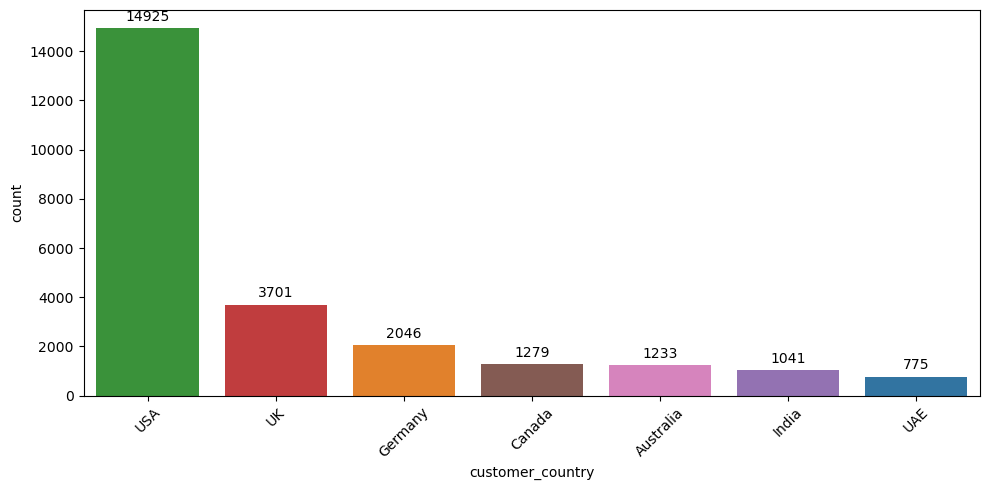

In [162]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("customer_master.csv")

# 1. Calculate the descending order of the countries
ordered_countries = df['customer_country'].value_counts().index

fig, ax = plt.subplots(figsize=(10, 5))

# 2. Use countplot instead of histplot, and pass the ordered list
ax = sns.countplot(
    data=df, 
    x='customer_country', 
    order=ordered_countries, 
    hue='customer_country', 
    dodge=False # Keeps bars aligned properly when using hue
)

# 3. Clean up the duplicate legend
if ax.get_legend():
    ax.get_legend().remove()

# 4. Add the labels (same as before)
for container in ax.containers:
    labels = [f'{int(v.get_height())}' if v.get_height() > 0 else '' for v in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.xticks(rotation=45) # Optional: Rotates the country names so they don't overlap
plt.tight_layout()
plt.show()

In [176]:
ordered_countries

Index(['USA', 'UK', 'Germany', 'Canada', 'Australia', 'India', 'UAE'], dtype='object', name='customer_country')

In [198]:
percentage_country = df['customer_country'].value_counts(normalize=True).reset_index()

In [200]:
percentage_country.columns = ['Country', 'Percentage%']

In [202]:
percentage_country['Percentage%'] = np.round(percentage_county['Percentage%'] * 100,2)

In [204]:
percentage_country

,Country,Percentage%
0,USA,59.70
1,UK,14.80
2,Germany,8.18
3,Canada,5.12
4,Australia,4.93
5,India,4.16
6,UAE,3.10


## Region Isn't a Single Global Axis
### region has 5 values, but check whether they mean the same thing in every country before comparing across it.

In [211]:
pd.crosstab(df['customer_country'],df['region']).reset_index()

region,customer_country,Central,East,North,South,West
0,Australia,0,252,191,536,254
1,Canada,525,473,0,0,281
2,Germany,415,0,397,804,430
3,India,0,0,223,424,394
4,UAE,0,0,371,404,0
5,UK,0,0,1840,0,1861
6,USA,4418,3149,0,5828,1530


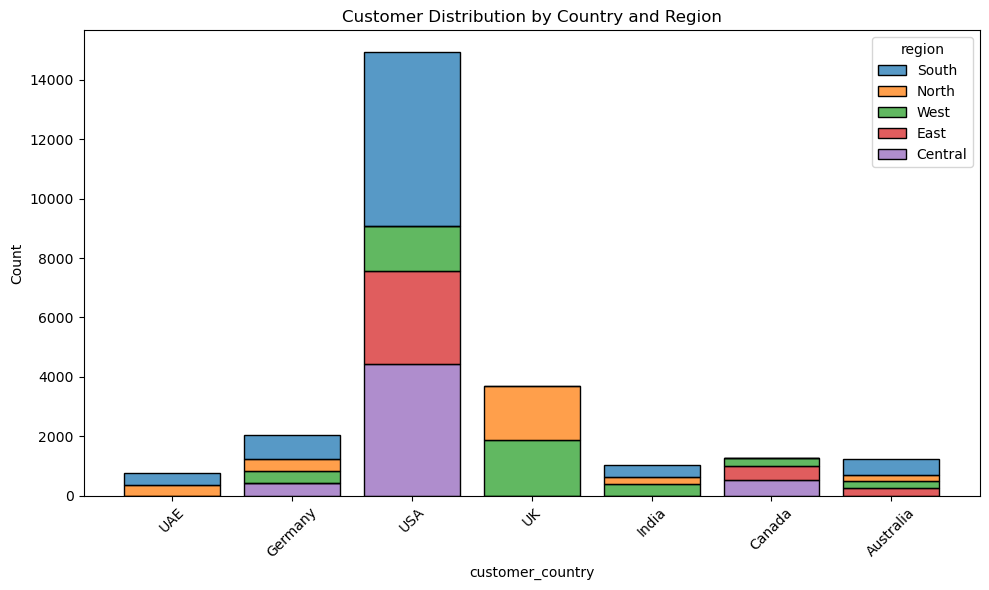

In [215]:
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the distribution of countries, broken down by region
sns.histplot(
    data=df, 
    x='customer_country', 
    hue='region', 
    multiple='stack', # Use 'stack' for stacked bars, or 'dodge' for side-by-side bars
    shrink=0.8
)

plt.xticks(rotation=45) # Rotate x-axis labels so country names don't overlap
plt.title("Customer Distribution by Country and Region")
plt.tight_layout()
plt.show()

In [261]:
print("Segment mix is nearly identical in every country:")
print(np.round(pd.crosstab(df['customer_country'],df['customer_segment'],normalize='index') * 100,2))
print()
print("Acquisition cost barely moves by segment:")
print(df.groupby('customer_segment',as_index=False)['customer_acquisition_cost'].mean().round(2))

Segment mix is nearly identical in every country:
customer_segment  Business  Consumer  Premium    VIP
customer_country                                    
Australia            10.95     53.61    25.06  10.38
Canada               10.01     53.24    27.05   9.70
Germany               9.34     55.67    25.27   9.73
India                11.05     52.45    25.74  10.76
UAE                   9.55     53.94    25.94  10.58
UK                    9.75     55.04    24.75  10.46
USA                  10.15     54.65    25.09  10.12

Acquisition cost barely moves by segment:
  customer_segment  customer_acquisition_cost
0         Business                      42.38
1         Consumer                      42.26
2          Premium                      41.94
3              VIP                      41.93


## Acquisition Cost Distribution
### The shape of the one continuous financial field in this file.

In [288]:
mean_customer_acq = np.round(df['customer_acquisition_cost'].mean(),2)
median_customer_acq = np.round(df['customer_acquisition_cost'].median(),2)

print(f'Customer acquisition mean is {mean_customer_acq} and median is {median_customer_acq}')

Customer acquisition mean is 42.16 and median is 41.98


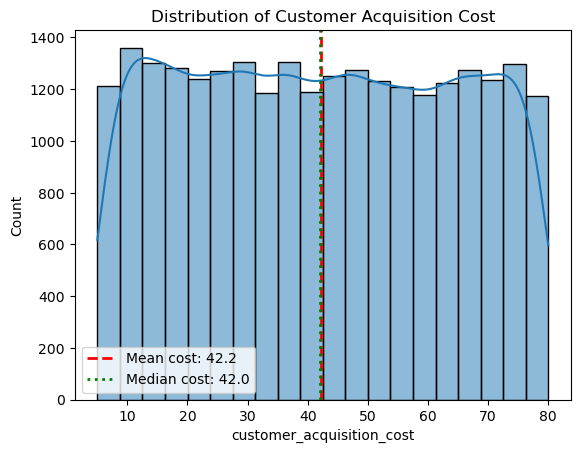

In [293]:
sns.histplot(data=df, x='customer_acquisition_cost', bins=20, kde=True)

plt.axvline(mean_customer_acq, color='red', linestyle='--', linewidth=2, label=f'Mean cost: {mean_customer_acq:.1f}')
plt.axvline(median_customer_acq, color='green', linestyle=':', linewidth=2, label=f'Median cost: {median_customer_acq:.1f}')

plt.legend()
plt.title("Distribution of Customer Acquisition Cost")
plt.show()

In [297]:
max_age = df['customer_age'].max()
min_age = df['customer_age'].min()
print(f"Age Range: {min_age} to {max_age}")


Age Range: 18 to 74


In [299]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

features = ['customer_age', 'customer_acquisition_cost', 'customer_country']
X = df[features]
y = df['customer_segment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), ['customer_age', 'customer_acquisition_cost']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['customer_country'])
])
clf = Pipeline([('prep', preprocess), ('model', RandomForestClassifier(n_estimators=200, random_state=42))])
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"Macro F1: {f1_score(y_test, pred, average='macro'):.3f}")
print(f"Baseline (always predict Consumer): {(y_test == 'Consumer').mean():.3f}")

Accuracy: 0.384
Macro F1: 0.236
Baseline (always predict Consumer): 0.546


## RFM K-MEAN CLUSTERING 

In [113]:
df_two = pd.read_csv(r"C:\Users\DELL\Desktop\Programming\Data analytics\work\E-commerce sales analytics\ecommerce_sales_customer_analytics_150k.csv")
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [114]:
df_two.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [115]:
row, column = df_two.shape
print(f"The table has {column} columns and {row} rows ")
print("-----------Description---------------")
df.describe()

The table has 46 columns and 138116 rows 
-----------Description---------------


,customer_age,customer_postal_code,customer_acquisition_cost
count,25000.000000,25000.000000,25000.000000
mean,45.907840,50183.066400,42.159750
std,16.454286,28596.584321,21.692648
min,18.000000,516.000000,5.010000
25%,32.000000,25374.500000,23.297500
50%,46.000000,50303.000000,41.980000
75%,60.000000,74845.500000,61.130000
max,74.000000,99950.000000,79.990000


In [116]:
df_two.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

In [117]:
print("-----------Nulls---------------")
print(df_two.isnull().sum())
print("-----------NA---------------")

print(df_two.isna().sum())
print("------------Duplicates----------------")

df.duplicated().sum()
print(f"Duplicate customer_id: {df_two['order_id'].duplicated().sum()}")

-----------Nulls---------------
order_id                         0
order_date                       0
order_time                       0
order_status                     0
sales_channel                    0
customer_id                      0
customer_name                    0
customer_age                     0
gender                           0
customer_segment                 0
customer_type                    0
customer_city                    0
customer_state                   0
customer_country                 0
region                           0
customer_postal_code             0
payment_method                   0
payment_status                   0
currency                         0
shipping_method                  0
warehouse                        0
delivery_days                24557
estimated_delivery_days      24557
delivery_status                  0
return_status               128654
return_reason               128654
customer_rating              24557
review_sentiment       

In [118]:
df_two['order_date'] = pd.to_datetime(df_two['order_date'])

In [119]:
order_date_max = df_two['order_date'].max()

In [193]:
rf_tbl = df_two.groupby('customer_id').agg({
    
    'order_date': lambda x: (order_date_max - x.max()).days,
    'order_id':'nunique',
    'gross_sales': 'sum'
    
}).rename(columns = {

    'order_date': 'Recency',
    'order_id' : 'Frequency',
    'gross_sales' : 'Monetary'
    
})

rf_tbl.head()

,Recency,Frequency,Monetary
customer_id,,,
CUST-000001,6,9,10260.22
CUST-000002,282,10,16602.49
CUST-000003,209,7,7244.70
CUST-000004,54,7,14330.31
CUST-000005,412,8,12375.10


In [197]:
rf_tbl['Frequency'].max()

19

In [199]:
scaler = StandardScaler()
scaled_rfm_tbl = scaler.fit_transform(rf_tbl)

In [201]:
scaled_rfm_tbl

array([[-0.97324763,  1.49061705,  0.59655998],
       [-0.07079213,  1.92197704,  2.03267444],
       [-0.30948507,  0.62789709, -0.08626051],
       ...,
       [-0.73782445,  1.05925707, -0.46762075],
       [ 2.0807141 , -1.96026281, -1.45142144],
       [-0.97324763, -0.66618286, -0.27182659]])

Text(0, 0.5, 'Inertia')

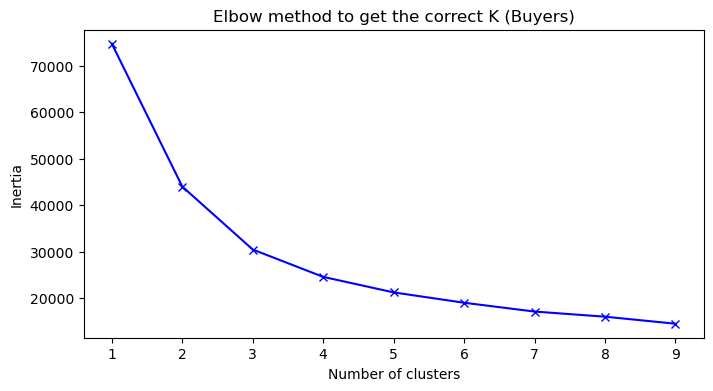

In [204]:
k_list = []

for k in range(1,10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(scaled_rfm_tbl)
    k_list.append(kmeans.inertia_)


plt.figure(figsize=(8,4))
plt.plot(range(1,10), k_list, 'bx-')
plt.title('Elbow method to get the correct K (Buyers)')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

In [206]:
kmeans = KMeans(n_clusters=4, random_state=42)
cluster = kmeans.fit_predict(scaled_rfm_tbl)

In [208]:
rf_tbl['Cluster'] = cluster +1 

In [210]:
rf_tbl

,Recency,Frequency,Monetary,Cluster
customer_id,,,,
CUST-000001,6,9,10260.22,1
CUST-000002,282,10,16602.49,1
CUST-000003,209,7,7244.70,3
CUST-000004,54,7,14330.31,1
CUST-000005,412,8,12375.10,1
...,...,...,...,...
CUST-024996,57,7,12665.72,1
CUST-024997,700,3,1224.75,4
CUST-024998,78,8,5560.51,3


In [212]:
clusters_summary_buyers = rf_tbl.groupby('Cluster').mean().round(2)
print('='*10+'Clusters buyers summary'+'='*10)
print(clusters_summary_buyers)

==========Clusters buyers summary==========
         Recency  Frequency  Monetary
Cluster                              
1         155.13       8.93  14765.56
2         221.90       3.89   4332.34
3         202.96       6.42   8727.94
4         876.91       3.36   4423.50


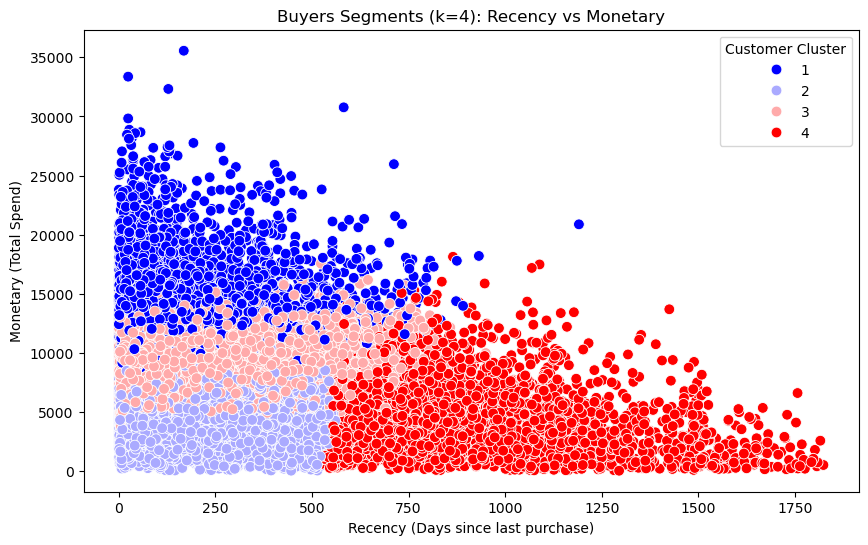

In [228]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=rf_tbl, x='Recency', y='Monetary', hue='Cluster',palette='bwr',s=60)
plt.title(f'Buyers Segments (k={4}): Recency vs Monetary')
plt.xlabel('Recency (Days since last purchase)')
plt.ylabel('Monetary (Total Spend)')
plt.legend(title='Customer Cluster')